

# Cohort Retention and Customer Lifetime Value (CLV) Analysis

**Domain:** E-commerce / Retail Analytics  |  **Role:** Data Analyst  |  **Tools:** Python, pandas, matplotlib, seaborn

**Problem statement:** An online retail business wants to know how many customers come back after their first purchase, which signup months bring the best customers, and how much revenue a customer brings over time. This notebook builds a monthly cohort retention table and a simple CLV view so the business can decide where to spend on retention.

**What this notebook does**
1. Loads transaction data (real Online Retail data if download works, otherwise a realistic sample)
2. Cleans the data
3. Builds monthly cohorts and a retention heatmap
4. Calculates revenue per customer by cohort (cumulative CLV)
5. Finds top 20% customers and their revenue share
6. Prints the key insights and saves charts

In [1]:
!pip install -q pandas matplotlib seaborn kagglehub

## Step 1: Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, glob
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
np.random.seed(42)
print("libraries ready")

libraries ready


## Step 2: Load the data
First I try the real Online Retail dataset from Kaggle. If it does not download, a sample dataset with the same columns is created so the notebook still runs.

In [3]:
def make_sample_data():
    rows = []
    months = pd.date_range("2024-01-01", periods=12, freq="MS")
    customer_id = 10000
    invoice = 500000
    for m_index in range(12):
        n_new = np.random.randint(90, 160)
        for i in range(n_new):
            customer_id = customer_id + 1
            start_month = months[m_index]
            retention_chance = np.random.uniform(0.25, 0.55)
            for later in range(m_index, 12):
                if later == m_index:
                    buy = True
                else:
                    gap = later - m_index
                    buy = np.random.rand() < retention_chance * (0.88 ** gap)
                if buy:
                    n_orders = np.random.randint(1, 4)
                    for o in range(n_orders):
                        invoice = invoice + 1
                        day = np.random.randint(0, 27)
                        date = months[later] + pd.Timedelta(days=int(day))
                        n_items = np.random.randint(1, 5)
                        for k in range(n_items):
                            rows.append([invoice, customer_id, date, np.random.randint(1, 8), round(np.random.uniform(2, 45), 2)])
    data = pd.DataFrame(rows, columns=["InvoiceNo", "CustomerID", "InvoiceDate", "Quantity", "UnitPrice"])
    return data

df = None
try:
    import kagglehub
    path = kagglehub.dataset_download("carrie1/ecommerce-data")
    files = glob.glob(path + "/**/*.csv", recursive=True)
    df = pd.read_csv(files[0], encoding="latin1")
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df = df[["InvoiceNo", "CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]]
    data_source = "Real Online Retail dataset (Kaggle)"
except Exception as e:
    print("Kaggle download did not work, using sample data instead")
    df = make_sample_data()
    data_source = "Sample data (same columns as Online Retail)"

print("Data source:", data_source)
print("Shape:", df.shape)
df.head()

100%|██████████| 7.20M/7.20M [00:00<00:00, 63.9MB/s]

Extracting files...


Data source: Real Online Retail dataset (Kaggle)
Shape: (541909, 5)


,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice
0,536365,17850.0,2010-12-01 08:26:00,6,2.55
1,536365,17850.0,2010-12-01 08:26:00,6,3.39
2,536365,17850.0,2010-12-01 08:26:00,8,2.75
3,536365,17850.0,2010-12-01 08:26:00,6,3.39
4,536365,17850.0,2010-12-01 08:26:00,6,3.39


## Step 3: Clean the data
Removing rows without a customer id, returns (negative quantity) and zero prices.

In [4]:
print("rows before cleaning:", len(df))

df = df.dropna(subset=["CustomerID"])
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]
df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("rows after cleaning:", len(df))
print("customers:", df["CustomerID"].nunique())
print("total revenue:", round(df["Revenue"].sum(), 2))
print("date range:", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())

rows before cleaning: 541909
rows after cleaning: 397884
customers: 4338
total revenue: 8911407.9
date range: 2010-12-01 to 2011-12-09


## Step 4: Build the cohorts
A cohort = the month a customer made their first purchase. Cohort index = how many months after that first month.

In [5]:
df["OrderMonth"] = df["InvoiceDate"].dt.to_period("M")
df["CohortMonth"] = df.groupby("CustomerID")["OrderMonth"].transform("min")

df["CohortIndex"] = (df["OrderMonth"].dt.year - df["CohortMonth"].dt.year) * 12 + (df["OrderMonth"].dt.month - df["CohortMonth"].dt.month)

cohort_counts = df.groupby(["CohortMonth", "CohortIndex"])["CustomerID"].nunique().reset_index()
cohort_table = cohort_counts.pivot(index="CohortMonth", columns="CohortIndex", values="CustomerID")

cohort_size = cohort_table[0]
retention = cohort_table.divide(cohort_size, axis=0) * 100
retention = retention.round(1)

print("Cohort sizes (customers who joined each month):")
print(cohort_size)
retention.head()

Cohort sizes (customers who joined each month):
CohortMonth
2010-12    885.0
2011-01    417.0
2011-02    380.0
2011-03    452.0
2011-04    300.0
2011-05    284.0
2011-06    242.0
2011-07    188.0
2011-08    169.0
2011-09    299.0
2011-10    358.0
2011-11    323.0
2011-12     41.0
Freq: M, Name: 0, dtype: float64


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.6,32.3,38.4,36.3,39.8,36.3,34.9,35.4,39.5,37.4,50.3,26.6
2011-01,100.0,22.1,26.6,23.0,32.1,28.8,24.7,24.2,30.0,32.6,36.5,11.8,NaN
2011-02,100.0,18.7,18.7,28.4,27.1,24.7,25.3,27.9,24.7,30.5,6.8,NaN,NaN
2011-03,100.0,15.0,25.2,19.9,22.3,16.8,26.8,23.0,27.9,8.6,NaN,NaN,NaN
2011-04,100.0,21.3,20.3,21.0,19.7,22.7,21.7,26.0,7.3,NaN,NaN,NaN,NaN


## Step 5: Retention heatmap

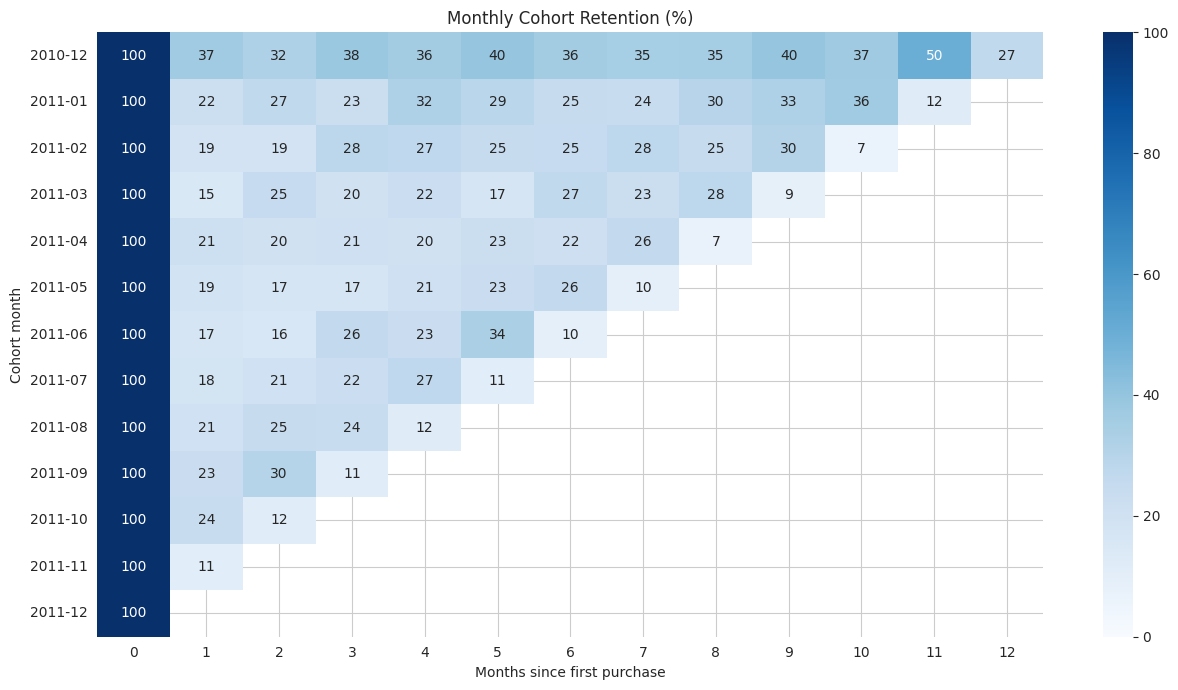

In [6]:
plt.figure(figsize=(13, 7))
sns.heatmap(retention, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100)
plt.title("Monthly Cohort Retention (%)")
plt.xlabel("Months since first purchase")
plt.ylabel("Cohort month")
plt.tight_layout()
plt.savefig("cohort_retention_heatmap.png", dpi=150)
plt.show()

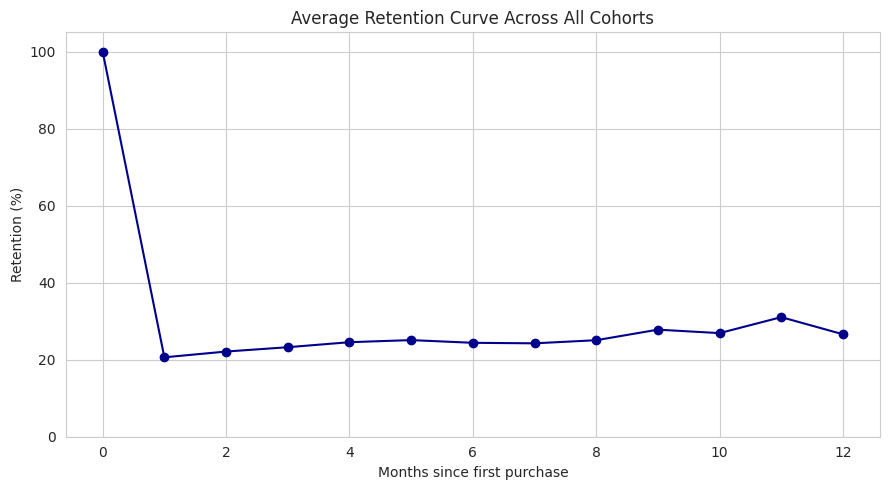

Average retention by month:
CohortIndex
0     100.0
1      20.6
2      22.1
3      23.2
4      24.5
5      25.1
6      24.4
7      24.2
8      25.1
9      27.8
10     26.9
11     31.0
12     26.6
dtype: float64


In [7]:
avg_retention = retention.mean()
plt.figure(figsize=(9, 5))
plt.plot(avg_retention.index, avg_retention.values, marker="o", color="darkblue")
plt.title("Average Retention Curve Across All Cohorts")
plt.xlabel("Months since first purchase")
plt.ylabel("Retention (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("average_retention_curve.png", dpi=150)
plt.show()

print("Average retention by month:")
print(avg_retention.round(1))

## Step 6: Customer Lifetime Value (CLV) by cohort
Cumulative revenue per customer for each cohort, month by month. This is the historical CLV.

In [8]:
revenue_table = df.groupby(["CohortMonth", "CohortIndex"])["Revenue"].sum().reset_index()
revenue_table = revenue_table.pivot(index="CohortMonth", columns="CohortIndex", values="Revenue")
revenue_table = revenue_table.fillna(0)

cum_revenue = revenue_table.cumsum(axis=1)
clv_table = cum_revenue.divide(cohort_size, axis=0)

# remove cells that are in the future for that cohort
clv_table = clv_table.where(cohort_table.notna())
clv_table = clv_table.round(2)
clv_table.head()

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,647.13,959.27,1223.50,1566.01,1796.98,2177.35,2532.33,2883.50,3258.36,3792.61,4307.96,4888.53,5098.47
2011-01,703.14,835.39,987.11,1158.78,1353.30,1556.14,1724.26,1898.58,2071.30,2339.41,2636.49,2699.96,NaN
2011-02,416.16,492.59,600.84,727.79,833.44,923.50,1054.31,1218.65,1364.39,1534.94,1562.83,NaN,NaN
2011-03,442.63,509.14,639.79,734.52,848.81,937.35,1080.98,1238.11,1395.78,1424.25,NaN,NaN,NaN
2011-04,406.70,504.88,588.47,669.51,757.22,857.91,953.47,1067.57,1088.74,NaN,NaN,NaN,NaN


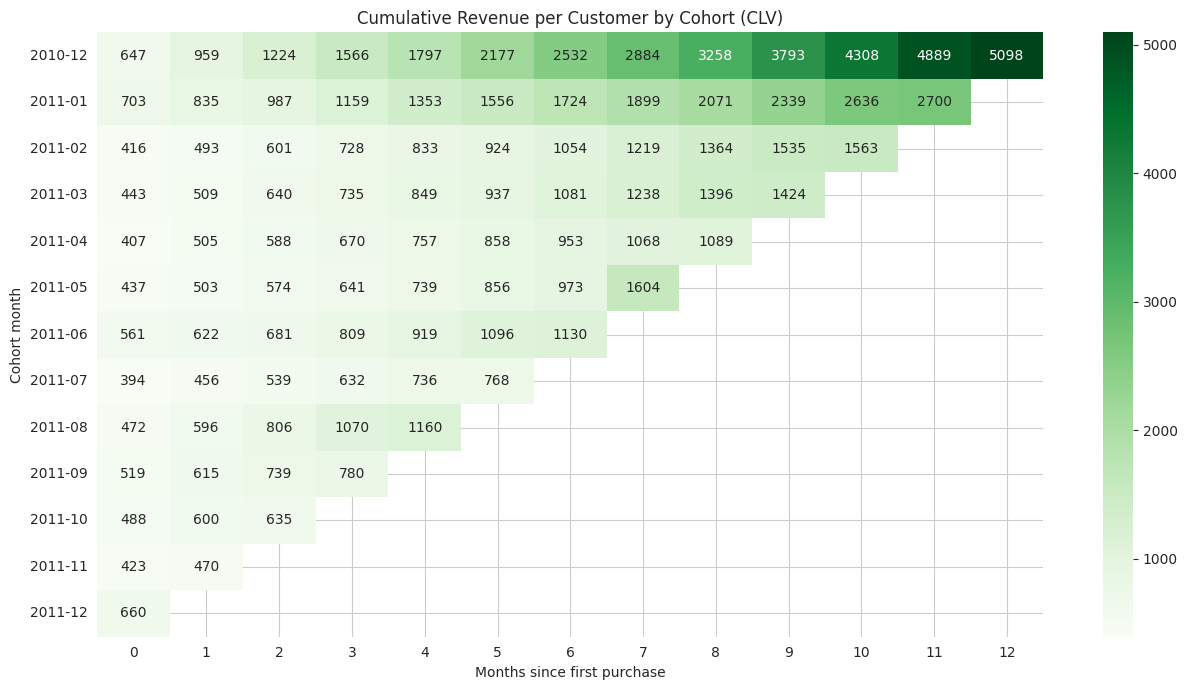

In [9]:
plt.figure(figsize=(13, 7))
sns.heatmap(clv_table, annot=True, fmt=".0f", cmap="Greens")
plt.title("Cumulative Revenue per Customer by Cohort (CLV)")
plt.xlabel("Months since first purchase")
plt.ylabel("Cohort month")
plt.tight_layout()
plt.savefig("clv_by_cohort_heatmap.png", dpi=150)
plt.show()

In [10]:
# 3 month CLV and 6 month CLV for cohorts that have that much history
clv_summary = pd.DataFrame()
clv_summary["Cohort Size"] = cohort_size
clv_summary["First Month Revenue per Customer"] = clv_table[0]
clv_summary["3 Month CLV"] = clv_table[3] if 3 in clv_table.columns else np.nan
clv_summary["6 Month CLV"] = clv_table[6] if 6 in clv_table.columns else np.nan
clv_summary["Month 3 Retention %"] = retention[3] if 3 in retention.columns else np.nan
print(clv_summary.round(2))

best_cohort = clv_summary["3 Month CLV"].idxmax()
worst_cohort = clv_summary["3 Month CLV"].idxmin()
print("\nBest cohort by 3 month CLV:", best_cohort, "->", round(clv_summary["3 Month CLV"].max(), 2))
print("Weakest cohort by 3 month CLV:", worst_cohort, "->", round(clv_summary["3 Month CLV"].min(), 2))

             Cohort Size  First Month Revenue per Customer  3 Month CLV  \
CohortMonth                                                               
2010-12            885.0                            647.13      1566.01   
2011-01            417.0                            703.14      1158.78   
2011-02            380.0                            416.16       727.79   
2011-03            452.0                            442.63       734.52   
2011-04            300.0                            406.70       669.51   
2011-05            284.0                            436.99       641.35   
2011-06            242.0                            560.92       808.53   
2011-07            188.0                            393.66       632.36   
2011-08            169.0                            471.93      1069.61   
2011-09            299.0                            518.74       780.26   
2011-10            358.0                            488.05          NaN   
2011-11            323.0 

## Step 7: Customer value segments
How much of the revenue comes from the top customers?

In [11]:
customer_data = df.groupby("CustomerID").agg(
    total_revenue=("Revenue", "sum"),
    orders=("InvoiceNo", "nunique"),
    first_order=("InvoiceDate", "min"),
    last_order=("InvoiceDate", "max")
).reset_index()

customer_data["avg_order_value"] = customer_data["total_revenue"] / customer_data["orders"]
customer_data = customer_data.sort_values("total_revenue", ascending=False).reset_index(drop=True)

top_20_count = int(len(customer_data) * 0.2)
top_20_revenue = customer_data.loc[:top_20_count, "total_revenue"].sum()
top_20_share = top_20_revenue / customer_data["total_revenue"].sum() * 100

print("Total customers:", len(customer_data))
print("Average revenue per customer:", round(customer_data["total_revenue"].mean(), 2))
print("Average orders per customer:", round(customer_data["orders"].mean(), 2))
print("Average order value:", round(customer_data["avg_order_value"].mean(), 2))
print("Top 20% customers give", round(top_20_share, 1), "% of the revenue")

one_time = (customer_data["orders"] == 1).sum()
print("One-time customers:", one_time, "(", round(one_time / len(customer_data) * 100, 1), "% )")

Total customers: 4338
Average revenue per customer: 2054.27
Average orders per customer: 4.27
Average order value: 419.17
Top 20% customers give 74.6 % of the revenue
One-time customers: 1493 ( 34.4 % )


            customers     revenue  avg_orders  revenue_share_%
segment                                                       
Top 20%           867  6647378.01       11.76             74.6
Middle 40%       1735  1818474.21        3.40             20.4
Bottom 40%       1736   445555.68        1.40              5.0


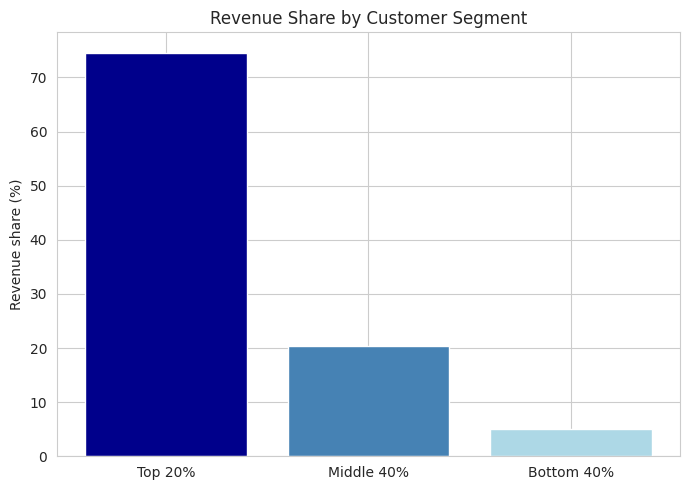

In [12]:
customer_data["segment"] = pd.cut(customer_data["total_revenue"].rank(pct=True, ascending=False),
                                  bins=[0, 0.2, 0.6, 1.0], labels=["Top 20%", "Middle 40%", "Bottom 40%"])
seg = customer_data.groupby("segment").agg(customers=("CustomerID", "count"), revenue=("total_revenue", "sum"), avg_orders=("orders", "mean"))
seg["revenue_share_%"] = (seg["revenue"] / seg["revenue"].sum() * 100).round(1)
print(seg.round(2))

plt.figure(figsize=(7, 5))
plt.bar(seg.index.astype(str), seg["revenue_share_%"], color=["darkblue", "steelblue", "lightblue"])
plt.title("Revenue Share by Customer Segment")
plt.ylabel("Revenue share (%)")
plt.tight_layout()
plt.savefig("revenue_share_by_segment.png", dpi=150)
plt.show()

## Step 8: Key insights (calculated from the output above)

In [13]:
month1 = avg_retention.get(1, np.nan)
month3 = avg_retention.get(3, np.nan)
month6 = avg_retention.get(6, np.nan)

print("KEY INSIGHTS")
print("-" * 50)
print("1. Data used:", data_source)
print("2. Customers analysed:", len(customer_data), "| Total revenue:", round(df["Revenue"].sum(), 0))
print("3. Average retention -> Month 1:", round(month1, 1), "% | Month 3:", round(month3, 1), "% | Month 6:", round(month6, 1), "%")
print("4. Biggest drop is between month 0 and month 1 (100% ->", round(month1, 1), "%), so the first 30 days decide retention")
print("5. Best cohort by 3 month CLV:", best_cohort, "| Weakest:", worst_cohort)
print("6. Top 20% customers bring", round(top_20_share, 1), "% of revenue")
print("7. One-time customers are", round(one_time / len(customer_data) * 100, 1), "% of all customers")
print()
print("RECOMMENDATIONS")
print("- Send a welcome offer / follow-up in the first 30 days to improve month 1 retention")
print("- Build a loyalty or VIP programme for the top 20% customers")
print("- Re-target one-time customers with a second-purchase discount")

KEY INSIGHTS
--------------------------------------------------
1. Data used: Real Online Retail dataset (Kaggle)
2. Customers analysed: 4338 | Total revenue: 8911408.0
3. Average retention -> Month 1: 20.6 % | Month 3: 23.2 % | Month 6: 24.4 %
4. Biggest drop is between month 0 and month 1 (100% -> 20.6 %), so the first 30 days decide retention
5. Best cohort by 3 month CLV: 2010-12 | Weakest: 2011-07
6. Top 20% customers bring 74.6 % of revenue
7. One-time customers are 34.4 % of all customers

RECOMMENDATIONS
- Send a welcome offer / follow-up in the first 30 days to improve month 1 retention
- Build a loyalty or VIP programme for the top 20% customers
- Re-target one-time customers with a second-purchase discount


In [14]:
clv_summary.to_csv("clv_summary_by_cohort.csv")
retention.to_csv("cohort_retention_table.csv")
customer_data.to_csv("customer_level_data.csv", index=False)
print("Saved files:", [f for f in os.listdir(".") if f.endswith(".png") or f.endswith(".csv")])

Saved files: ['revenue_share_by_segment.png', 'cohort_retention_table.csv', 'customer_level_data.csv', 'cohort_retention_heatmap.png', 'average_retention_curve.png', 'clv_by_cohort_heatmap.png', 'clv_summary_by_cohort.csv']


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)

---
*Built by Akshat Kesharwani | Portfolio: https://akshatkesharwani-info.github.io/ | GitHub: https://github.com/akshatkesharwani-info*